# Monitor de dengue em Alagoas · E1: download e qualidade dos dados

Primeira entrega do projeto. Este notebook mostra o que foi baixado, quando, e se a base está pronta para as análises das próximas etapas.

**Antes de rodar:** execute os três scripts de `src/` a partir da pasta raiz do repositório (o passo a passo está no README).

In [1]:
import json
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FuncFormatter

# Funciona tanto rodando de dentro de notebooks/ quanto da raiz do repositório
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TRATADOS = RAIZ / "data" / "processed"
FIGURAS = RAIZ / "reports" / "figures"
FIGURAS.mkdir(parents=True, exist_ok=True)

semanal = pd.read_csv(TRATADOS / "dengue_al_semanal.csv", parse_dates=["data_iniSE"])
anual = pd.read_csv(TRATADOS / "dengue_al_anual.csv")
resumo = json.loads((TRATADOS / "resumo_qualidade.json").read_text(encoding="utf-8"))

# Cores dos gráficos: uma cor para a série, tons de cinza para texto, grade e eixo
COR_SERIE = "#2a78d6"
SUPERFICIE = "#fcfcfb"
TEXTO = "#0b0b0b"
TEXTO_2 = "#52514e"
TEXTO_MUDO = "#898781"
GRADE = "#e1e0d9"
EIXO = "#c3c2b7"

plt.rcParams.update({
    "figure.facecolor": SUPERFICIE,
    "axes.facecolor": SUPERFICIE,
    "axes.edgecolor": EIXO,
    "axes.titlecolor": TEXTO,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "xtick.color": TEXTO_MUDO,
    "ytick.color": TEXTO_MUDO,
    "font.size": 10,
})


def milhar(valor, _=None):
    """Formata números no padrão brasileiro: 12.345"""
    return f"{valor:,.0f}".replace(",", ".")

## 1. O que foi baixado e quando

| Fonte | O que traz | Acesso |
|---|---|---|
| InfoDengue (Fiocruz e FGV) | casos de dengue por semana epidemiológica e município: notificados (`casos`), prováveis (`casprov`, notificados menos descartados) e estimados com correção do atraso de notificação (`casos_est`); nível de alerta; temperatura e umidade | API `alertcity` |
| IBGE (SIDRA) | população por município: estimativas anuais (tabela 6579) e Censo 2022 (tabela 4709) | API SIDRA |

In [2]:
pd.Series({
    "InfoDengue baixado em": resumo["infodengue_baixado_em"].replace("T", " "),
    "População do IBGE baixada em": resumo["populacao_baixada_em"].replace("T", " "),
    "Municípios": resumo["municipios"],
    "Primeira semana epidemiológica": resumo["primeira_semana"],
    "Última semana epidemiológica": resumo["ultima_semana"],
    "Linhas na base semanal": milhar(len(semanal)),
}, name="valor").to_frame()

,valor
InfoDengue baixado em,2026-11-09 21:26
População do IBGE baixada em,2026-11-09 21:27
Municípios,102
Primeira semana epidemiológica,201501
Última semana epidemiológica,202553
Linhas na base semanal,58.548


## 2. Checagens de qualidade

Antes de qualquer gráfico, a base precisa passar por estas checagens. A coluna "esperado" diz o que um resultado sem problemas mostra.

In [3]:
semanas = semanal.groupby("geocode").size()
intervalos = semanal.groupby("geocode")["data_iniSE"].diff().dt.days.dropna()
anos_sem_pop = anual.loc[anual["pop"].isna(), "ano"].unique().tolist()

pd.DataFrame([
    ("Municípios na base", semanal["geocode"].nunique(), 102),
    ("Semanas por município (mín. e máx.)", f"{semanas.min()} e {semanas.max()}", "iguais"),
    ("Semanas duplicadas", int(semanal.duplicated(["geocode", "SE"]).sum()), 0),
    ("Buracos na série (intervalo diferente de 7 dias)", int((intervalos != 7).sum()), 0),
    ("Casos negativos", int((semanal["casos"] < 0).sum()), 0),
    ("Anos sem população do IBGE", ", ".join(map(str, anos_sem_pop)) or "nenhum", "nenhum"),
], columns=["checagem", "resultado", "esperado"]).set_index("checagem")

,resultado,esperado
checagem,,
Municípios na base,102,102
Semanas por município (mín. e máx.),574 e 574,iguais
Semanas duplicadas,0,0
Buracos na série (intervalo diferente de 7 dias),0,0
Casos negativos,0,0
Anos sem população do IBGE,nenhum,nenhum


Valores nulos por coluna (só aparecem as colunas com algum nulo):

In [4]:
nulos = (semanal.isna().mean() * 100).round(1)
nulos[nulos > 0].sort_values(ascending=False).to_frame("% de valores nulos")

,% de valores nulos
umidmed,2.8
tempmed,1.9


### A população do InfoDengue não serve para comparar anos

A coluna `pop` do InfoDengue (aqui `pop_infodengue`) fica constante de 2015 a 2022 e muda de patamar em 2023, para valores próximos aos do Censo 2022. As estimativas do IBGE para os anos anteriores eram projeções feitas a partir do Censo 2010, e o Censo 2022 contou menos gente em muitos municípios. Por isso a incidência anual deste projeto usa a população do IBGE de cada ano. 2023 não tem estimativa oficial e foi interpolado entre 2022 e 2024.

In [5]:
pop_info = semanal.groupby(["ano", "geocode"])["pop_infodengue"].mean().groupby("ano").sum()
pop_ibge = anual.groupby("ano")["pop"].sum()

comparacao = pd.DataFrame({"InfoDengue": pop_info, "IBGE": pop_ibge})
comparacao["diferença (%)"] = ((comparacao["InfoDengue"] / comparacao["IBGE"] - 1) * 100).round(1)
comparacao[["InfoDengue", "IBGE"]] = comparacao[["InfoDengue", "IBGE"]].apply(lambda coluna: coluna.map(milhar))
comparacao.rename_axis("população de Alagoas")

,InfoDengue,IBGE,diferença (%)
população de Alagoas,,,
2015,3.351.543,3.340.932,0.3
2016,3.351.543,3.358.963,-0.2
2017,3.351.543,3.375.823,-0.7
2018,3.351.543,3.322.820,0.9
2019,3.351.543,3.337.357,0.4
2020,3.351.543,3.351.543,0.0
2021,3.351.543,3.365.351,-0.4
2022,3.351.543,3.127.683,7.2
2023,3.147.013,3.173.894,-0.8


## 3. Série semanal de Alagoas

Soma dos casos prováveis dos 102 municípios em cada semana epidemiológica. Os valores das semanas mais recentes ainda podem subir, porque o InfoDengue atualiza a série retroativamente toda semana.

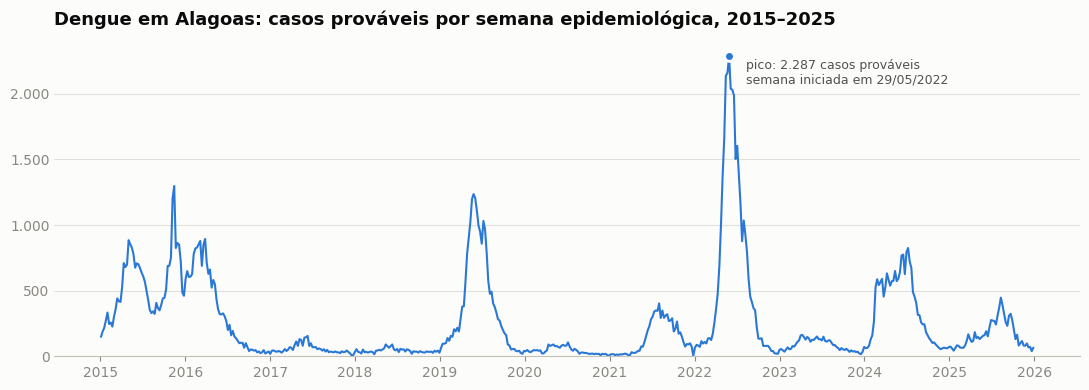

In [6]:
serie = semanal.groupby("data_iniSE")["casprov"].sum()
pico = serie.idxmax()
texto_a_direita = pico < serie.index[int(len(serie) * 0.7)]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(serie.index, serie.values, color=COR_SERIE, linewidth=1.5,
        solid_joinstyle="round", solid_capstyle="round")
ax.plot(pico, serie[pico], "o", markersize=7, color=COR_SERIE,
        markeredgecolor=SUPERFICIE, markeredgewidth=2)
ax.annotate(f"pico: {milhar(serie[pico])} casos prováveis\nsemana iniciada em {pico:%d/%m/%Y}",
            xy=(pico, serie[pico]), xytext=(12 if texto_a_direita else -12, -2),
            textcoords="offset points", ha="left" if texto_a_direita else "right",
            va="top", color=TEXTO_2, fontsize=9)

ax.set_title("Dengue em Alagoas: casos prováveis por semana epidemiológica, 2015–2025", pad=12)
ax.yaxis.set_major_formatter(FuncFormatter(milhar))
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_ylim(bottom=0)
ax.grid(axis="y", color=GRADE, linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
fig.tight_layout()
fig.savefig(FIGURAS / "serie_semanal_al.png", dpi=150)
plt.show()

## 4. Municípios com maior incidência em 2024

Incidência = casos prováveis no ano ÷ população do IBGE × 100 mil habitantes. Municípios pequenos oscilam mais, porque poucos casos já mudam muito a taxa; a etapa E3 trata disso.

In [7]:
top10 = (anual[anual["ano"] == 2024]
         .nlargest(10, "incidencia_100k")
         [["municipio", "casos_provaveis", "pop", "incidencia_100k"]]
         .reset_index(drop=True))
top10.index = top10.index + 1
top10["pop"] = top10["pop"].round().astype(int)
top10.round({"incidencia_100k": 1})

,municipio,casos_provaveis,pop,incidencia_100k
1,Maragogi,941,33232,2831.6
2,Feira Grande,533,23191,2298.3
3,Pão de Açúcar,420,24291,1729.0
4,Palmeira dos Índios,1153,73596,1566.7
5,Japaratinga,139,9443,1472.0
6,Roteiro,76,6607,1150.3
7,Arapiraca,2413,243661,990.3
8,Santana do Ipanema,464,47397,979.0
9,Maceió,8632,994464,868.0
10,Marechal Deodoro,515,62341,826.1


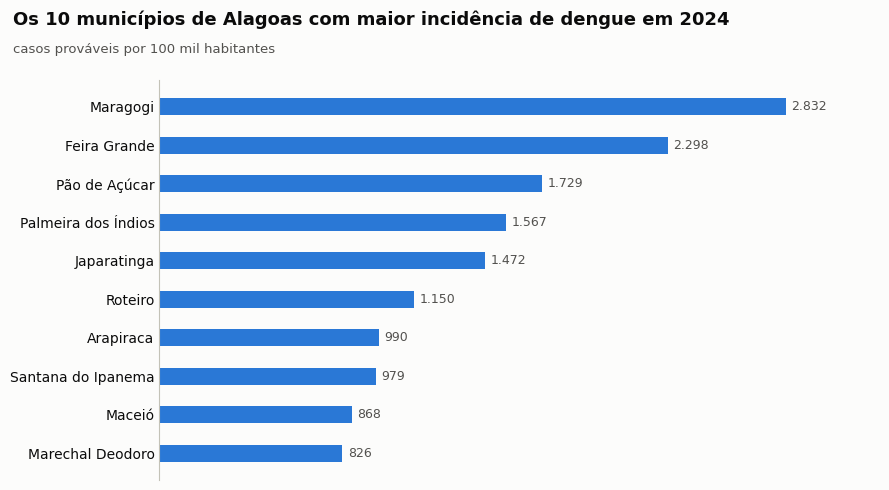

In [8]:
dados = top10.sort_values("incidencia_100k")

fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.barh(dados["municipio"], dados["incidencia_100k"], height=0.45, color=COR_SERIE)
ax.bar_label(barras, labels=[milhar(v) for v in dados["incidencia_100k"]],
             padding=4, color=TEXTO_2, fontsize=9)

# Título e subtítulo alinhados à borda esquerda da figura, para não serem cortados
fig.suptitle("Os 10 municípios de Alagoas com maior incidência de dengue em 2024",
             x=0.02, y=0.97, ha="left", fontsize=13, fontweight="bold", color=TEXTO)
fig.text(0.02, 0.885, "casos prováveis por 100 mil habitantes", ha="left",
         color=TEXTO_2, fontsize=9.5)
ax.set_xlim(0, dados["incidencia_100k"].max() * 1.15)
ax.xaxis.set_visible(False)
ax.tick_params(axis="y", length=0, labelcolor=TEXTO)
ax.spines[["top", "right", "bottom"]].set_visible(False)
fig.tight_layout()
fig.subplots_adjust(top=0.83)  # espaço para o título e o subtítulo
fig.savefig(FIGURAS / "top10_incidencia_2024.png", dpi=150)
plt.show()

## 5. Totais anuais para conferir com o TabNet

Compare estes totais com o TabNet do DATASUS: na seção de doenças e agravos de notificação (SINAN), escolha dengue, Alagoas, ano e município de residência. Diferenças pequenas são esperadas, porque as bases são atualizadas em datas diferentes. Anote no README as que encontrar.

In [9]:
totais = anual.groupby("ano").agg(
    casos_notificados=("casos_notificados", "sum"),
    casos_provaveis=("casos_provaveis", "sum"),
    populacao_ibge=("pop", "sum"),
)
totais["incidencia_100k"] = (totais["casos_provaveis"] / totais["populacao_ibge"] * 100_000).round(1)
colunas = ["casos_notificados", "casos_provaveis", "populacao_ibge"]
totais[colunas] = totais[colunas].apply(lambda coluna: coluna.map(milhar))
totais

,casos_notificados,casos_provaveis,populacao_ibge,incidencia_100k
ano,,,,
2015,35.034,28.370,3.340.932,849.2
2016,23.311,17.881,3.358.963,532.3
2017,3.612,2.910,3.375.823,86.2
2018,2.990,2.221,3.322.820,66.8
2019,27.418,20.894,3.337.357,626.1
2020,3.623,2.318,3.351.543,69.2
2021,9.257,7.337,3.365.351,218.0
2022,42.425,32.337,3.127.683,1033.9
2023,6.865,4.431,3.173.894,139.6


## Próximos passos

- **E2 · visualização:** mapa de calor município × semana e mapa da incidência anual por município (malhas do pacote `geobr`).
- **E3 · estatística:** canal endêmico por município, ou por região de saúde nos municípios pequenos, e lista das semanas acima do limite.
- Antes da E3, decidir como tratar 2020 e 2021, anos com possível subnotificação ligada à pandemia.